## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [1]:
import requests
URL_LAUREATES = f'https://api.nobelprize.org/2.1/laureates?limit=1200'

laureates_response = requests.get(
    URL_LAUREATES,
    headers = {
        "User-Agent": "Mozilla/5.0"
    })
laureates = laureates_response.json()

In [2]:
from laureates_configs import process_orgs, process_persons  # реализуйте эти функции согласно описанной выше логике

def get_laureate_data(laureate):
    """Определяет тип лауреата и обрабатывает его данные с помощью соответствующей функции"""
    if "knownName" in laureate:
        result = process_persons(laureate)
        result["type_"] = "person"
    elif "orgName" in laureate:
        result = process_orgs(laureate)
        result["type_"] = "org"
    else:
        return None

    return result

Проверю работу функции на одной записи из Nobel Prize API: сравню извлеченные значения с исходными данными, чтобы убедиться в корректности обработки вложенных словарей.

In [3]:
test_laureate = laureates["laureates"][0]
test_result = get_laureate_data(test_laureate)

assert test_result["id"] == test_laureate["id"]
assert test_result["gender"] == test_laureate["gender"]
assert test_result["birth_year"] == int(test_laureate["birth"]["year"])
assert test_result["country_birth"] == test_laureate["birth"]["place"]["country"]["en"]

print("Все проверки пройдены успешно")

Все проверки пройдены успешно


In [4]:
laureates_data = []

for laureate in laureates['laureates']:
    laureates_data.append(get_laureate_data(laureate))



### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

## Первичный анализ данных

**Объём и структура данных**

In [5]:
from dataset_helpers import group_by

In [6]:
print("Всего записей:", len(laureates_data))

types = group_by(laureates_data, "type_")

print("Физические лица:", len(types["person"]))
print("Организации:", len(types["org"]))

Всего записей: 1028
Физические лица: 1000
Организации: 28


Датасет состоит из 1028 записей и включает 1000 лауреатов-физических лиц и 28 организаций.

**Анализ пропусков**

In [7]:
from aggregations import count_missing

In [8]:
missing = count_missing(laureates_data)
print("Число пропущенных значений:")
print(missing)

Число пропущенных значений:
{'id': 0, 'name': 0, 'gender': 28, 'birth_year': 28, 'country_birth': 31, 'country_now': 7, 'prizes_relevant': 0, 'type_': 0, 'founded_year': 1001, 'country_founded': 1004}


In [9]:
print("Доля пропущенных значений:")
for field, value in missing.items():
    share = round(value / len(laureates_data) * 100, 2)
    print(f"{field}: {share}%")

Доля пропущенных значений:
id: 0.0%
name: 0.0%
gender: 2.72%
birth_year: 2.72%
country_birth: 3.02%
country_now: 0.68%
prizes_relevant: 0.0%
type_: 0.0%
founded_year: 97.37%
country_founded: 97.67%


Значительная часть пропусков обусловлена различиями между физическими лицами и организациями:
* Поля gender и birth_year содержат по 28 пропусков, соответствующих числу организаций в датасете.
* Поля founded_year и country_founded содержат 1001 и 1004 пропуска соответственно. Из них по 1000 объясняются неприменимостью этих полей к физическим лицам, остальные связаны с отсутствием информации об отдельных организациях.

Также пропуски присутствуют в полях country_birth и country_now. При дальнейшем анализе используются записи с заполненными значениями признаков, необходимых для соответствующих расчётов.

**Проверка идентификаторов:**

In [10]:
ids = [int(laureate["id"]) for laureate in laureates_data]

print("Минимальный id:", min(ids))
print("Максимальный id:", max(ids))

Минимальный id: 1
Максимальный id: 1070


In [11]:
for laureate in laureates_data:
    if int(laureate["id"]) in (min(ids), max(ids)):
        years = [prize["award_year"] for prize in laureate["prizes_relevant"]]
        print(laureate["id"], laureate["name"], years)

1070 Michael Woodford [2026]
1 Wilhelm Conrad Röntgen [1901]


In [12]:
print("Количество повторяющихся id:", len(ids) - len(set(ids)))

Количество повторяющихся id: 0


In [13]:
sorted_ids = sorted(set(ids))

gaps = []

for i in range(len(sorted_ids) - 1):
    if sorted_ids[i + 1] - sorted_ids[i] > 1:
        gaps.append((sorted_ids[i], sorted_ids[i + 1]))

print("Количество промежутков между ID:", len(gaps))

Количество промежутков между ID: 24


Идентификаторы лауреатов находятся в диапазоне от 1 до 1070. Минимальный ID принадлежит Вильгельму Конраду Рентгену, получившему Нобелевскую премию в 1901 году, максимальный - Майклу Вудфорду, получившему награду в 2026 году.

Повторяющихся идентификаторов не обнаружено, однако выявлено 24 промежутка между последовательными ID. 


Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты? 

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз? 
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

Подготовлю общий список prizes_data для дальнейшего анализа нобелевских лауреатов по странам, возрастам и гендерному распределению. Каждая запись в списке соответствует одному награждению и содержит идентификатор лауреата, страну его рождения, пол, год рождения, категорию премии, год награждения и соответствующее десятилетие.

In [14]:
prizes_data = []

for laureate in laureates_data:
    if laureate["type_"] == "person":
        for prize in laureate["prizes_relevant"]:
            prizes_data.append({
                "id": laureate["id"],
                "country": laureate["country_birth"],
                "gender": laureate["gender"],
                "birth_year": laureate["birth_year"],
                "category": prize["category_en"],
                "award_year": prize["award_year"],
                "decade": prize["award_year"] // 10 * 10 + 10
            })

## **Топ статистика по странам**

In [15]:
import matplotlib.pyplot as plt
from aggregations import top_n

In [16]:
persons = [
    laureate for laureate in laureates_data
    if laureate["type_"] == "person"
    and laureate["country_birth"] is not None
]

countries = group_by(persons, "country_birth")

In [17]:
top_5 = top_n(countries, 5)

for country, laureates in top_5:
    print(f"{country}: {len(laureates)}")

USA: 299
United Kingdom: 94
Germany: 82
France: 61
Japan: 31


Наибольшее количество нобелевских лауреатов родились в США (299 человек) - это более чем втрое превышает показатель Великобритании (94 человека), занимающей второе место. Далее следуют Германия (82), Франция (61) и Япония (31).

**Визуализация представлена ниже:**

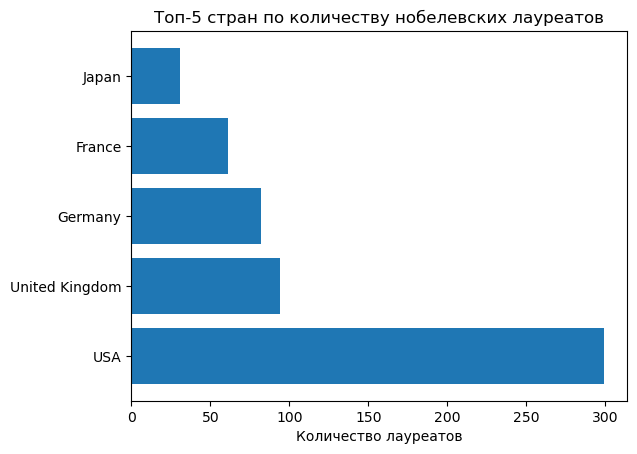

In [18]:
country_names = [country for country, laureates in top_5]
counts = [len(laureates) for country, laureates in top_5]

plt.barh(country_names, counts)
plt.xlabel("Количество лауреатов")
plt.title("Топ-5 стран по количеству нобелевских лауреатов")
plt.show()

**Анализ стран рождения лауреатов по категориям Нобелевской Премии:**

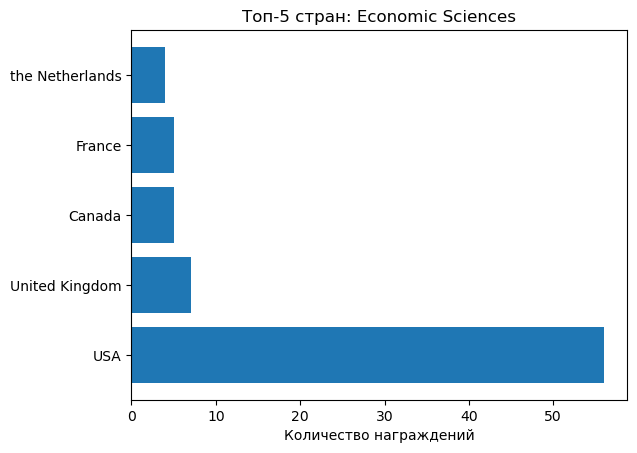

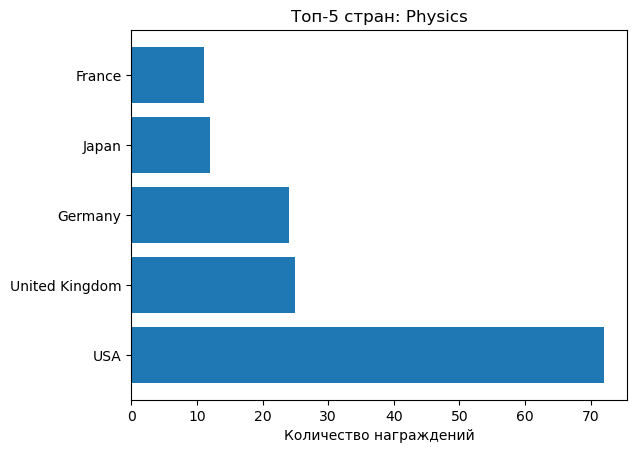

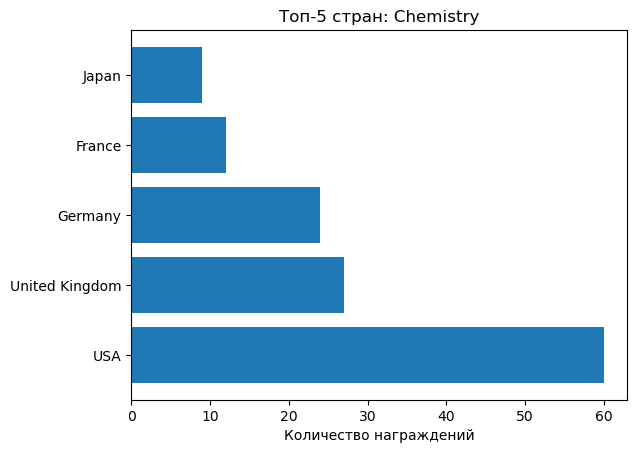

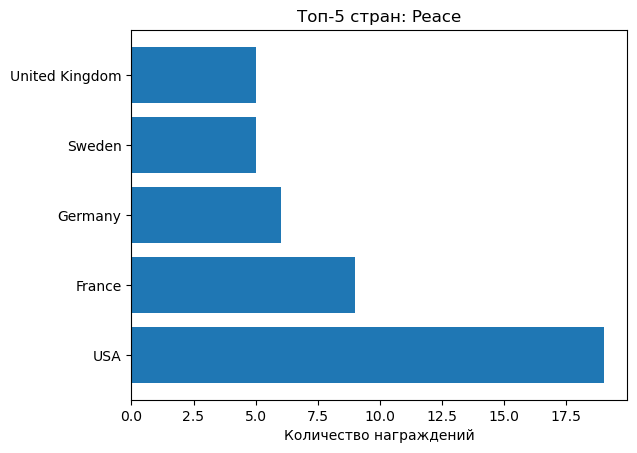

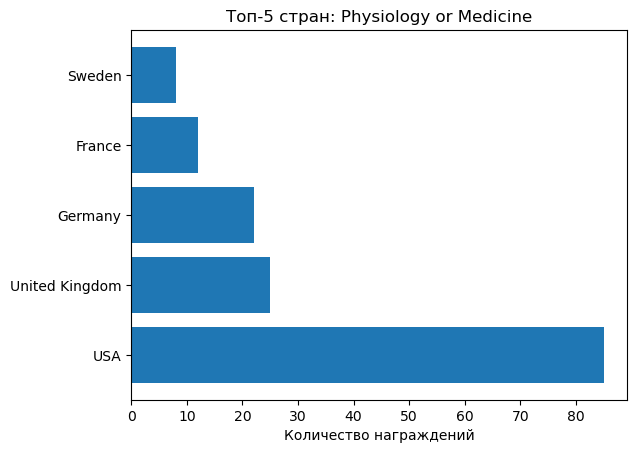

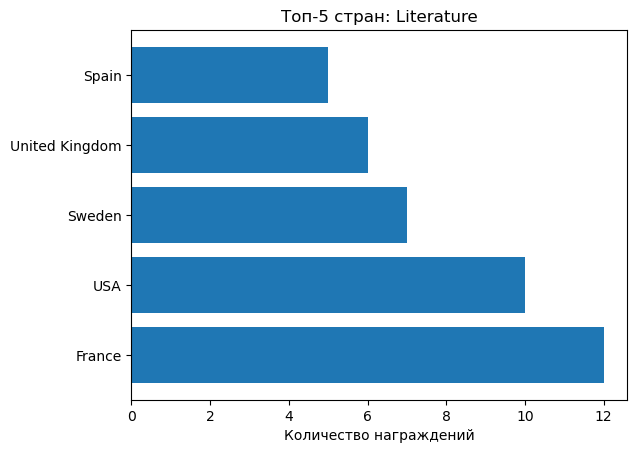

In [19]:
prizes_by_country = [
    prize for prize in prizes_data
    if prize["country"] is not None
]

categories = group_by(prizes_by_country, "category")

for category, prizes in categories.items():
    countries_by_category = group_by(prizes, "country")
    top_5_category = top_n(countries_by_category, 5)

    country_names = [country for country, laureates in top_5_category]
    counts = [len(laureates) for country, laureates in top_5_category]

    plt.barh(country_names, counts)
    plt.title(f"Топ-5 стран: {category}")
    plt.xlabel("Количество награждений")
    plt.show()

США лидируют по количеству награждений в пяти из шести категорий Нобелевской премии. Исключение составляет литература, где первое место занимает Франция (12 награждений), а США занимают второе место (10 награждений).

**Динамика награждений по странам:**

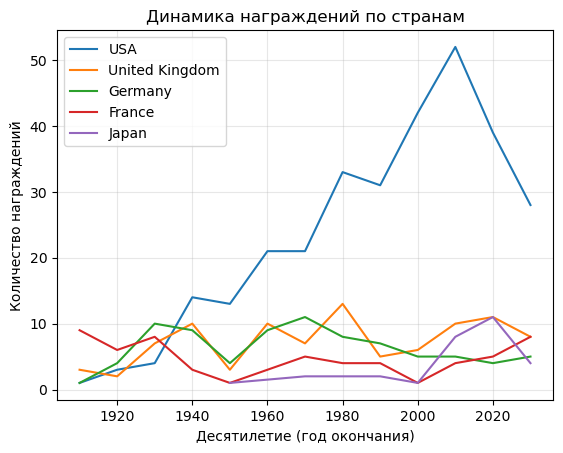

In [20]:
top_country_names = [country for country, laureates in top_5]

for country in top_country_names:
    country_prizes = [
        prize for prize in prizes_by_country
        if prize["country"] == country
    ]

    decades = group_by(country_prizes, "decade")
    decade_names = sorted(decades.keys())
    counts = [len(decades[decade]) for decade in decade_names]

    plt.plot(decade_names, counts, label=country)

plt.xlabel("Десятилетие (год окончания)")
plt.ylabel("Количество награждений")
plt.title("Динамика награждений по странам")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

С 1930-х годов США значительно опережают остальные страны по количеству награждений. Число награждений американских лауреатов росло до 2010-х годов, после чего снизилось на 25% по сравнению с предыдущим десятилетием (с 52 до 39 награждений). Отрицательная динамика сохраняется и в текущем десятилетии.

В остальных странах выраженного долгосрочного роста не наблюдается: количество награждений колеблется преимущественно в пределах 10 за десятилетие.

## **Возраст при награждении**

In [21]:
from atribute_manager import add_attribute
from aggregations import calculate_mean, calculate_median, calculate_mode

In [22]:
first_prizes = {}

for prize in prizes_data:
    laureate_id = prize["id"]

    if (laureate_id not in first_prizes
            or prize["award_year"] < first_prizes[laureate_id]["award_year"]):
        first_prizes[laureate_id] = prize

age_data = []

for prize in first_prizes.values():
    if prize["birth_year"] is not None:
        age_data.append({
            "birth_year": prize["birth_year"],
            "award_year": prize["award_year"],
            "decade": prize["decade"],
            "category": prize["category"]
        })
        
age_data = add_attribute(
    age_data,
    "age",
    lambda x: x["award_year"] - x["birth_year"]
)

**Распределение возраста среди нобелевских лауреатов:**

In [23]:
ages = [laureate["age"] for laureate in age_data]
mean_age = round(calculate_mean(ages), 1)
median_age = calculate_median(ages)
mode_age = calculate_mode(ages)
min_age = min(ages)
max_age = max(ages)

lst_ages = {
    "Средний возраст": mean_age,
    "Медианный возраст": median_age,
    "Мода возраста": mode_age,
    "Минимальный возраст": min_age,
    "Максимальный возраст": max_age
}

for name, age in lst_ages.items():
    if age % 10 == 1:
        word = "год"
    elif age % 10 in [2, 3, 4]:
        word = "года"
    else:
        word = "лет"

    print(f"{name}: {age} {word}")

Средний возраст: 60.6 лет
Медианный возраст: 61.0 год
Мода возраста: 56 лет
Минимальный возраст: 17 лет
Максимальный возраст: 97 лет


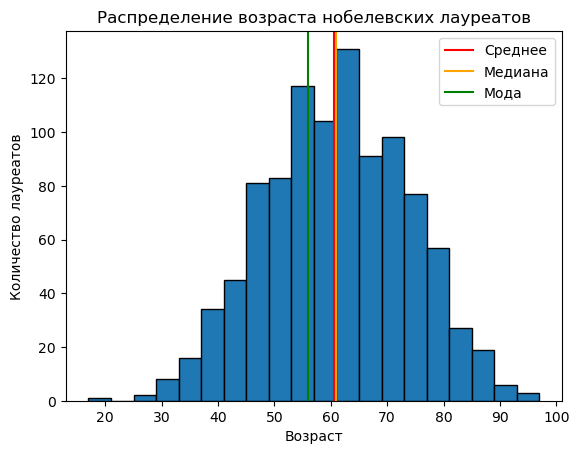

In [24]:
plt.hist(ages, bins=20, edgecolor="black")

plt.axvline(mean_age, color="red", label="Среднее")
plt.axvline(median_age, color="orange", label="Медиана")
plt.axvline(mode_age, color="green", label="Мода")

plt.title("Распределение возраста нобелевских лауреатов")
plt.xlabel("Возраст")
plt.ylabel("Количество лауреатов")
plt.legend()
plt.show()

Возраст нобелевских лауреатов на момент награждения варьируется от 17 до 97 лет. 
Средний возраст составляет 60,6 года, медианный - 61 год, наиболее часто встречающийся возраст (мода) - 56 лет. 
Близость среднего и медианы свидетельствует об отсутствии выраженной асимметрии распределения.

**Анализ среднего возраста нобелевских лауреатов по категориям:**

In [25]:
ages_by_category = group_by(age_data, "category")

category_names = []
average_ages = []

for category, laureates in ages_by_category.items():
    ages = [laureate["age"] for laureate in laureates]
    avg_age = calculate_mean(ages)
    category_names.append(category)
    average_ages.append(avg_age)
    age = round(avg_age)
    if age % 10 == 1:
        word = "год"
    elif age % 10 in [2, 3, 4]:
        word = "года"
    else:
        word = "лет"
    print(f"{category}: {age} {word}")

Economic Sciences: 67 лет
Physics: 58 лет
Chemistry: 59 лет
Literature: 65 лет
Peace: 61 год
Physiology or Medicine: 59 лет


Средний возраст нобелевских лауреатов составляет от 58 до 67 лет.
Наиболее высокий средний возраст лауреатов наблюдается в экономических науках, а наиболее низкий - в физике.

**Визуализация:**

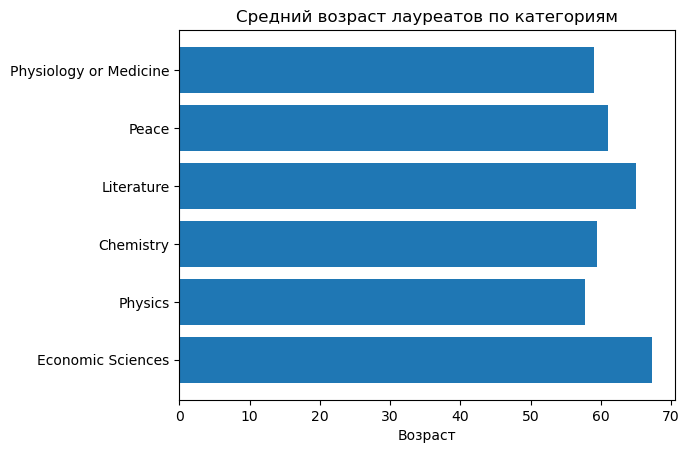

In [26]:
plt.barh(category_names, average_ages)
plt.title("Средний возраст лауреатов по категориям")
plt.xlabel("Возраст")
plt.show()

**Динамика среднего возраста нобелевских лауреатов:**

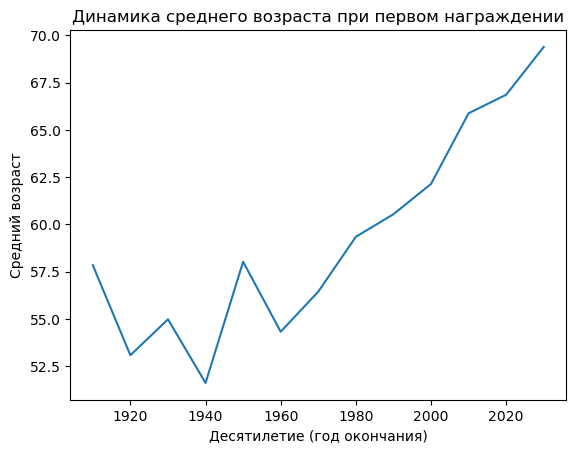

In [27]:
ages_by_decade = group_by(age_data, "decade")

decade_names = []
average_ages = []

for decade, laureates in sorted(ages_by_decade.items()):
    ages = [laureate["age"] for laureate in laureates]
    decade_names.append(decade)
    average_ages.append(calculate_mean(ages))

plt.plot(decade_names, average_ages)
plt.xlabel("Десятилетие (год окончания)")
plt.ylabel("Средний возраст")
plt.title("Динамика среднего возраста при первом награждении")
plt.show()

С 1960-х годов наблюдается устойчивый рост среднего возраста лауреатов при первом награждении. С 1960-х по 2020-е гг. он увеличился примерно с 54 до 67 лет, а в текущем десятилетии достиг почти 70 лет.

## **Гендерное распределение**

Мужчины: 931 человек
Женщины: 69 человек


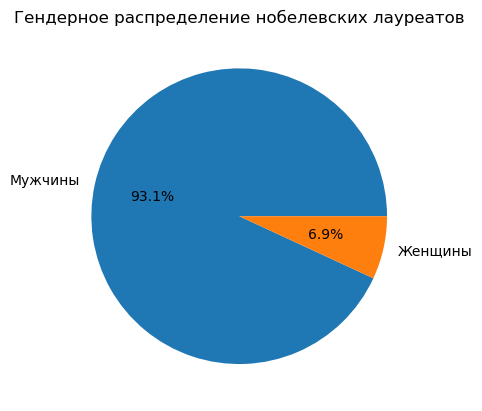

In [28]:
gender_data = [
    laureate for laureate in laureates_data
    if laureate["type_"] == "person"
    and laureate["gender"] is not None
]

genders = group_by(gender_data, "gender")

gender_names = []
counts = []

for gender, laureates in genders.items():
    name = "Мужчины" if gender == "male" else "Женщины"
    count = len(laureates)

    gender_names.append(name)
    counts.append(count)

    print(f"{name}: {count} человек")

plt.pie(counts, labels=gender_names, autopct="%1.1f%%")
plt.title("Гендерное распределение нобелевских лауреатов")
plt.show()

Среди нобелевских лауреатов значительно преобладают мужчины.

**Гендерное распределение по категориям:**

In [29]:
gender_dynamics = [
    prize for prize in prizes_data
    if prize["gender"] is not None
]

categories_gender = group_by(gender_dynamics, "category")

category_names = []
female_shares_category = []

for category, laureates in categories_gender.items():
    genders_category = group_by(laureates, "gender")

    male = len(genders_category.get("male", []))
    female = len(genders_category.get("female", []))
    female_share = round(female / len(laureates) * 100, 1)

    category_names.append(category)
    female_shares_category.append(female_share)

    print(f"{category}: мужчины - {male}, женщины - {female}, доля женщин - {female_share}%")

Economic Sciences: мужчины - 98, женщины - 3, доля женщин - 3.0%
Physics: мужчины - 226, женщины - 5, доля женщин - 2.2%
Chemistry: мужчины - 194, женщины - 8, доля женщин - 4.0%
Literature: мужчины - 104, женщины - 19, доля женщин - 15.4%
Peace: мужчины - 92, женщины - 21, доля женщин - 18.6%
Physiology or Medicine: мужчины - 221, женщины - 14, доля женщин - 6.0%


Доля женщин среди нобелевских лауреатов по категориям варьируется от 2 до 19%. Наименьшая доля женщин наблюдается в физике, а наибольшая - в категории «Нобелевская Премия мира».

**Визуализация:**

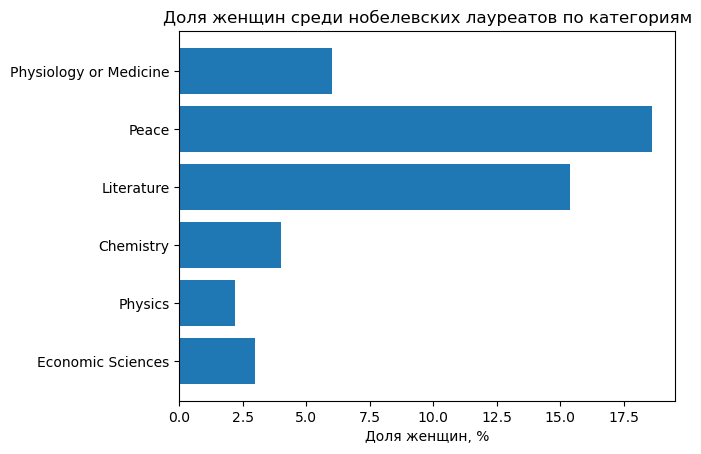

In [30]:
plt.barh(category_names, female_shares_category)
plt.title("Доля женщин среди нобелевских лауреатов по категориям")
plt.xlabel("Доля женщин, %")
plt.show()

**Гендерное распределение в динамике:**

In [31]:
decades = group_by(gender_dynamics, "decade")

decade_names = []
female_shares_decade = []

for decade, laureates in sorted(decades.items()):
    genders_decade = group_by(laureates, "gender")

    female = len(genders_decade.get("female", []))
    female_share = round(female / len(laureates) * 100, 1)

    decade_names.append(decade)
    female_shares_decade.append(female_share)

    print(f"{decade-10} - {decade}: число женщин - {female}, доля - {female_share}%")

1900 - 1910: число женщин - 3, доля - 5.4%
1910 - 1920: число женщин - 1, доля - 2.6%
1920 - 1930: число женщин - 2, доля - 3.7%
1930 - 1940: число женщин - 3, доля - 5.5%
1940 - 1950: число женщин - 3, доля - 7.5%
1950 - 1960: число женщин - 0, доля - 0.0%
1960 - 1970: число женщин - 3, доля - 4.0%
1970 - 1980: число женщин - 4, доля - 3.9%
1980 - 1990: число женщин - 4, доля - 4.3%
1990 - 2000: число женщин - 7, доля - 6.9%
2000 - 2010: число женщин - 11, доля - 9.2%
2010 - 2020: число женщин - 13, доля - 11.1%
2020 - 2030: число женщин - 16, доля - 19.5%


В 20 веке доля женщин среди нобелевских лауреатов преимущественно оставалась ниже 8%. Начиная с 2000-х годов наблюдается устойчивый рост с 6,9% в 1990-х до 19,5% в 2020-х годах. Такая динамика может свидетельствовать о расширении возможностей женщин в научной деятельности.

**Визуализация:**

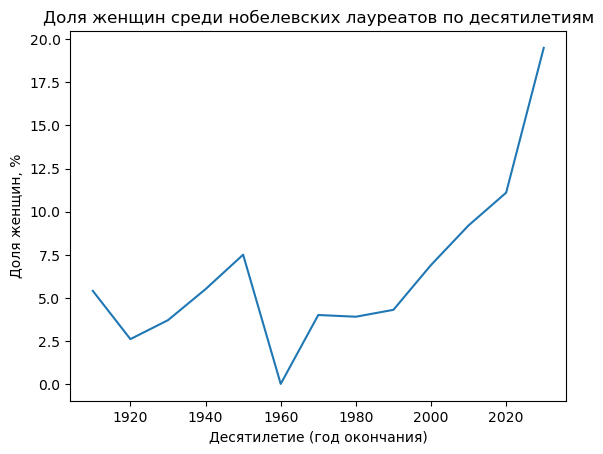

In [32]:
plt.plot(decade_names, female_shares_decade)
plt.title("Доля женщин среди нобелевских лауреатов по десятилетиям")
plt.xlabel("Десятилетие (год окончания)")
plt.ylabel("Доля женщин, %")
plt.show()

**Гендерное распределение в динамике по категориям:**

In [33]:
female_shares_by_category = {}

for category, records in categories_gender.items():
    decades = group_by(records, "decade")
    female_shares_by_category[category] = {}

    for decade, laureates_in_decade in decades.items():
        women = sum(
            1 for laureate in laureates_in_decade
            if laureate["gender"] == "female"
        )

        female_share = women / len(laureates_in_decade) * 100
        female_shares_by_category[category][decade] = female_share

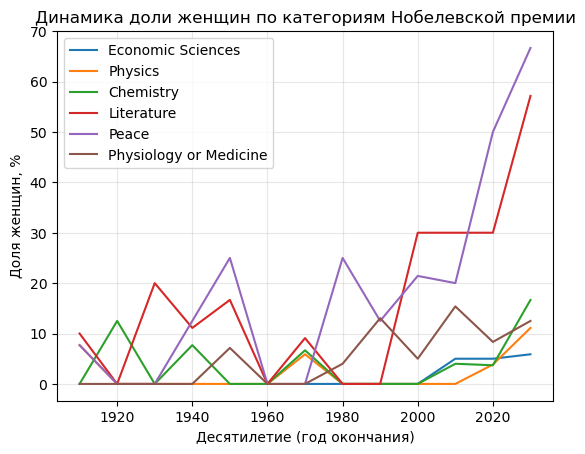

In [34]:
for category, shares in female_shares_by_category.items():
    decades = sorted(shares.keys())
    female_shares = [shares[decade] for decade in decades]

    plt.plot(decades, female_shares, label=category)

plt.xlabel("Десятилетие (год окончания)")
plt.ylabel("Доля женщин, %")
plt.title("Динамика доли женщин по категориям Нобелевской премии")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Наибольший рост доли женщин с 1980-х гг. наблюдается в категориях «Премия мира» и «Литература». В остальных категориях доля женщин остается значительно ниже, однако также наблюдается положительная динамика.

## **Выводы**

В ходе анализа данных о нобелевских лауреатах были выявлены следующие закономерности:

- **География:** США лидируют по количеству лауреатов и награждений, значительно опережая остальные страны. При этом после 2000-х годов наблюдается снижение числа награждений американских лауреатов.
- **Возраст:** Средний возраст лауреатов при первом награждении увеличивается с 1960-х годов и в последние годы достигает почти 70 лет.
- **Гендер:** Мужчины составляют подавляющее большинство нобелевских лауреатов (93,1%). Однако доля женщин постепенно увеличивается.


---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)